# GoogLeNet / Inception-v1 — From Scratch

### Learning objectives

By the end of this notebook, you should be able to:

- explain **why Inception was proposed**;
- describe the **Inception module** in simple words;
- explain why several filter sizes are used **in parallel**;
- explain what a **1×1 convolution** actually does;
- understand mathematically how a 1×1 convolution can **reduce channels**;
- explain why channel reduction may lose some information, but why it is still useful;
- explain why Inception **concatenates** feature maps instead of adding them;
- calculate feature-map dimensions inside an Inception block;
- understand **Global Average Pooling**;
- compare **AlexNet, VGG, Inception and ResNet**;
- implement **GoogLeNet / Inception-v1 using TensorFlow/Keras**.

---

## CNN evolution

$$
\boxed{
\text{LeNet} \rightarrow
\text{AlexNet} \rightarrow
\text{VGG} \rightarrow
\text{Inception / GoogLeNet} \rightarrow
\text{ResNet}
}
$$

A useful way to remember the progression:

- **LeNet:** CNNs work.
- **AlexNet:** CNNs can scale to large image datasets.
- **VGG:** go deeper using repeated small $3\times3$ convolutions.
- **Inception:** process the same input at **multiple scales in parallel**.
- **ResNet:** use shortcut connections to train very deep networks.

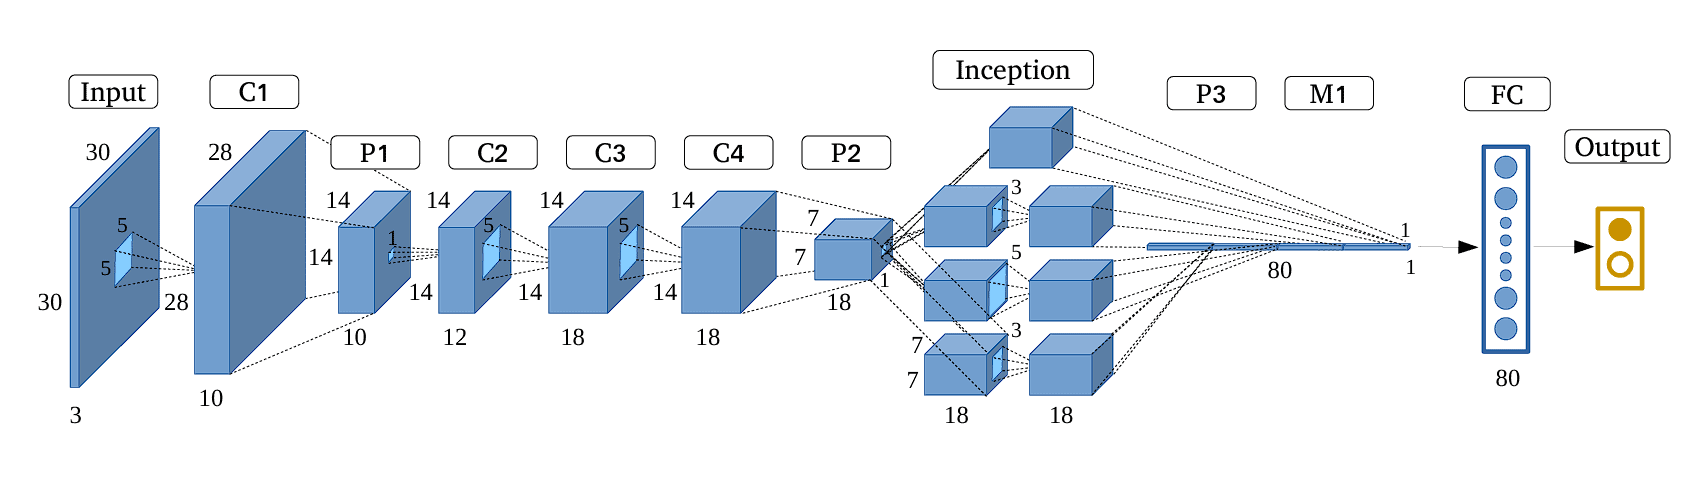

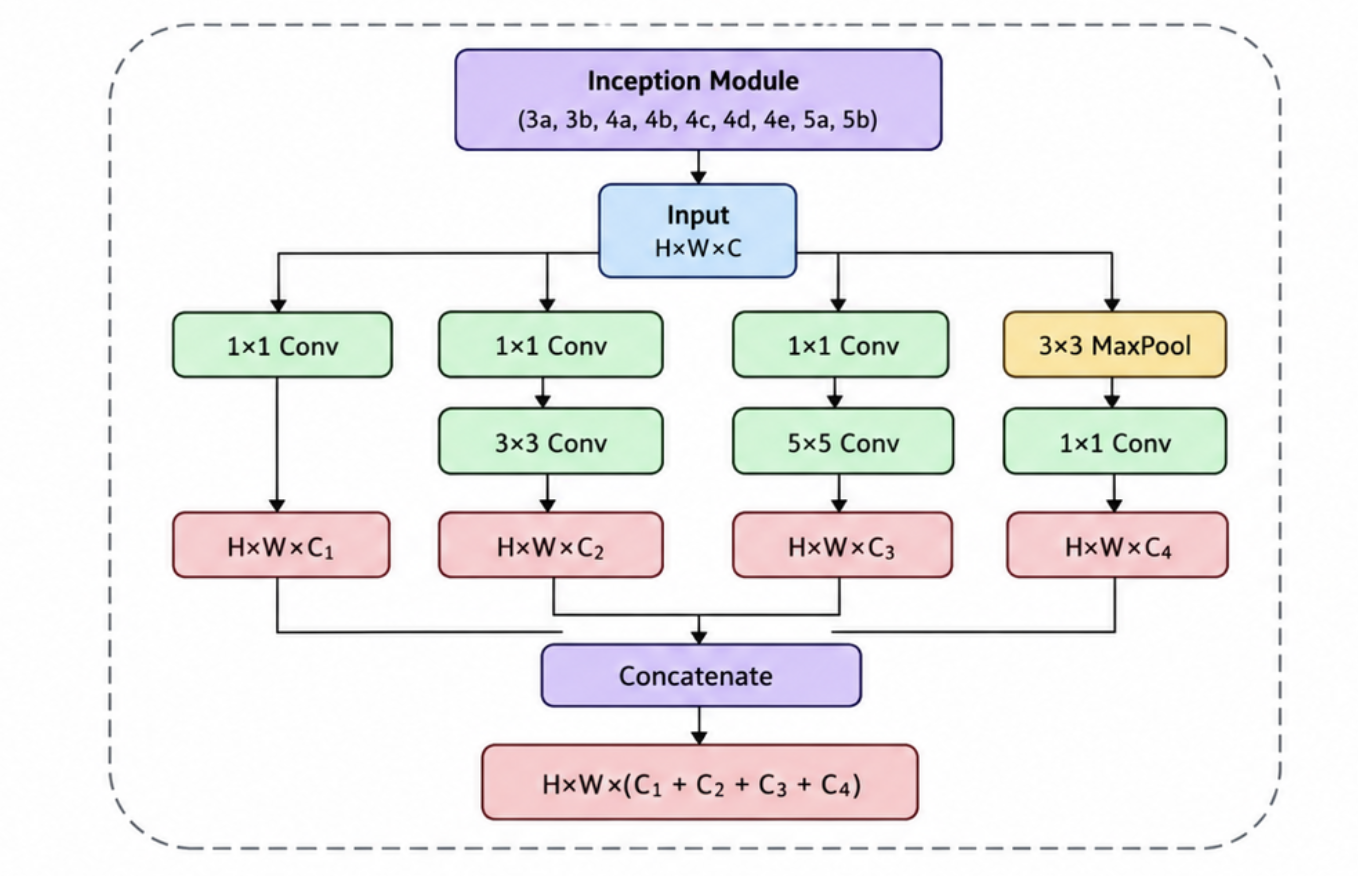

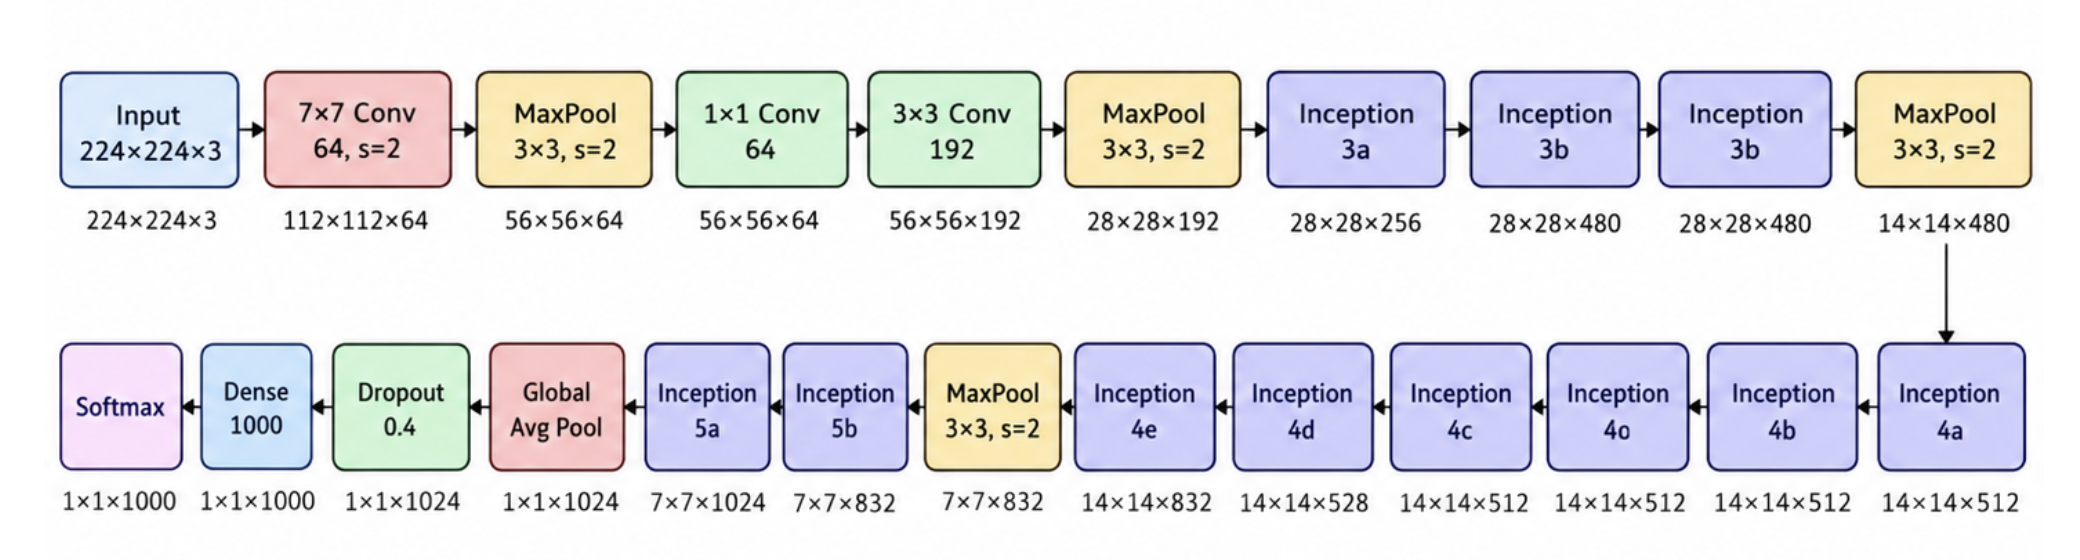

# 1. Why was Inception needed?

VGG showed that deeper CNNs can work very well.

But there was still an important question:

> **What filter size should we use at a particular layer?**

Different image patterns can have different spatial scales:

- small edge or texture → small receptive field;
- eye / corner / local shape → medium receptive field;
- larger object part → larger receptive field.

Instead of selecting only one filter size, Inception says:

> **Apply several operations to the same input in parallel and keep all the useful features.**

### Main idea

A typical Inception block contains parallel branches such as:

- $1\times1$ convolution;
- $1\times1 \rightarrow 3\times3$ convolution;
- $1\times1 \rightarrow 5\times5$ convolution;
- max pooling $\rightarrow 1\times1$ convolution.

Then the outputs are:

$$
\boxed{\text{concatenated along the channel dimension}}
$$

This lets the network learn **multi-scale features at the same stage**.

# 2. The basic Inception module

The same input goes into several branches:

```text
                         Input
                           │
          ┌────────────────┼────────────────┐
          │                │                │
          │                │                │
        1×1 Conv        1×1 Conv         1×1 Conv       Max Pool
          │                │                │                │
          │              3×3 Conv         5×5 Conv         1×1 Conv
          │                │                │                │
          └────────────────┴────────────────┴────────────────┘
                           │
                     Concatenate
                           │
                         Output
```

### Why parallel branches?

Each branch can focus on a different kind of representation:

- $1\times1$ branch → reduce the channel;
- $3\times3$ branch → medium spatial patterns;
- $5\times5$ branch → larger spatial patterns;
- pooling branch → summarized local information.

The exact interpretation is not fixed — the network learns the useful features automatically.

# 3. Worked example of one Inception module

Suppose the input is:

$$
\boxed{28\times28\times192}
$$

We use the following branches.

### Branch 1 — $1\times1$

Use 64 filters:

$$
28\times28\times192
\rightarrow
28\times28\times64
$$

---

### Branch 2 — $1\times1 \rightarrow 3\times3$

First reduce channels:

$$
28\times28\times192
\rightarrow
28\times28\times96
$$

Then apply 128 filters of size $3\times3$:

$$
28\times28\times96
\rightarrow
28\times28\times128
$$

---

### Branch 3 — $1\times1 \rightarrow 5\times5$

First reduce channels:

$$
28\times28\times192
\rightarrow
28\times28\times16
$$

Then apply 32 filters of size $5\times5$:

$$
28\times28\times16
\rightarrow
28\times28\times32
$$

---

### Branch 4 — MaxPool $\rightarrow 1\times1$

Pooling with stride 1 and same padding keeps the spatial size:

$$
28\times28\times192
\rightarrow
28\times28\times192
$$

Then use 32 filters of size $1\times1$:

$$
28\times28\times192
\rightarrow
28\times28\times32
$$

# 4. Feature-map size formula

For a convolution or pooling layer:

$$
\boxed{
O=
\left\lfloor
\frac{N-F+2P}{S}
\right\rfloor+1
}
$$

where:

- $N$ = input height or width;
- $F$ = filter size;
- $P$ = padding;
- $S$ = stride;
- $O$ = output height or width.

### Example — $3\times3$ convolution

Input:

$$
28\times28
$$

Use:

- $F=3$
- $P=1$
- $S=1$

Then:

$$
O=
\frac{28-3+2(1)}{1}+1
$$

$$
O=28
$$

So the spatial size remains:

$$
\boxed{28\times28}
$$

This is why **same padding** is useful when outputs from different branches must later be concatenated.

# 6. How does a $1\times1$ convolution reduce channels?

Suppose the input is:

$$
28\times28\times192
$$

Use **32 filters** of size:

$$
1\times1\times192
$$

Each filter produces **one output feature map**.

Therefore:

$$
\boxed{\text{number of output channels}=\text{number of filters}}
$$

So:

$$
192 \text{ input channels}
\rightarrow
32 \text{ output channels}
$$

and:

$$
\boxed{
28\times28\times192
\rightarrow
28\times28\times32
}
$$



# 11. Global Average Pooling

Near the end of GoogLeNet, **Global Average Pooling (GAP)** is used.

Suppose the final feature tensor is:

$$
7\times7\times1024
$$

For each of the 1024 channels, average all $7\times7$ values.

So:

$$
7\times7\times1024
\rightarrow
1\times1\times1024
$$

or simply:

$$
\boxed{1024}
$$

### Why use GAP?

- greatly reduces the number of classifier parameters;
- avoids a very large Flatten + Dense block;
- summarizes each feature map into one value.

This is an important difference from architectures such as AlexNet and VGG, which used large fully connected layers.

# 12. GoogLeNet / Inception-v1 architecture

The original GoogLeNet is built by stacking many Inception modules.

A simplified high-level flow is:

```text
Input 224×224×3
        ↓
7×7 Conv, 64, stride 2
        ↓
112×112×64
        ↓
3×3 MaxPool, stride 2
        ↓
56×56×64
        ↓
1×1 Conv, 64
        ↓
3×3 Conv, 192
        ↓
56×56×192
        ↓
MaxPool
        ↓
28×28×192
        ↓
Inception 3a
        ↓
28×28×256
        ↓
Inception 3b
        ↓
28×28×480
        ↓
MaxPool
        ↓
14×14×480
        ↓
Inception 4a
        ↓
Inception 4b
        ↓
Inception 4c
        ↓
Inception 4d
        ↓
Inception 4e
        ↓
14×14×832
        ↓
MaxPool
        ↓
7×7×832
        ↓
Inception 5a
        ↓
Inception 5b
        ↓
7×7×1024
        ↓
Global Average Pooling
        ↓
1024
        ↓
Dropout
        ↓
Dense 1000
        ↓
Softmax
```

## Inception-v1 module configurations

The standard branch widths used in the main GoogLeNet body are approximately:

| Module | 1×1 | 3×3 reduce | 3×3 | 5×5 reduce | 5×5 | Pool projection | Output channels |
|---|---:|---:|---:|---:|---:|---:|---:|
| 3a | 64 | 96 | 128 | 16 | 32 | 32 | 256 |
| 3b | 128 | 128 | 192 | 32 | 96 | 64 | 480 |
| 4a | 192 | 96 | 208 | 16 | 48 | 64 | 512 |
| 4b | 160 | 112 | 224 | 24 | 64 | 64 | 512 |
| 4c | 128 | 128 | 256 | 24 | 64 | 64 | 512 |
| 4d | 112 | 144 | 288 | 32 | 64 | 64 | 528 |
| 4e | 256 | 160 | 320 | 32 | 128 | 128 | 832 |
| 5a | 256 | 160 | 320 | 32 | 128 | 128 | 832 |
| 5b | 384 | 192 | 384 | 48 | 128 | 128 | 1024 |

You do **not** need to memorize every number.

For understanding, remember the design:

$$
\boxed{
1\times1,\quad
1\times1\rightarrow3\times3,\quad
1\times1\rightarrow5\times5,\quad
\text{Pool}\rightarrow1\times1
}
$$

# 14. AlexNet vs VGG vs Inception vs ResNet

| Architecture | Main idea |
|---|---|
| **AlexNet** | Large CNN, ReLU, dropout, GPU training |
| **VGG** | Go deeper using repeated $3\times3$ convolutions |
| **Inception** | Parallel multi-scale branches + concatenation |
| **ResNet** | Residual / shortcut connections + addition |

### Easy memory trick

$$
\boxed{\text{VGG = deeper}}
$$

$$
\boxed{\text{Inception = wider / multi-scale}}
$$

$$
\boxed{\text{ResNet = shortcuts}}
$$

# 16. Keras implementation

Now we will implement the architecture in TensorFlow / Keras.

We will build it in two steps:

1. create a reusable **Inception module**;
2. stack those modules to create the main **GoogLeNet / Inception-v1** network.

> The implementation below focuses on the main architecture. The original auxiliary classifiers and Local Response Normalization are omitted to keep the teaching code clear.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

## 17. Build one reusable Inception module

The function below creates four parallel branches:

1. $1\times1$
2. $1\times1 \rightarrow 3\times3$
3. $1\times1 \rightarrow 5\times5$
4. MaxPool $\rightarrow 1\times1$

The branch outputs are concatenated using:

```python
layers.Concatenate(axis=-1)
```

`axis=-1` means concatenate along the **channel dimension**.

In [ ]:
def inception_module(
    x,
    f1,
    f3_reduce, f3,
    f5_reduce, f5,
    pool_proj,
    name
):
    # Branch 1: 1x1 convolution
    branch1 = layers.Conv2D(
        f1, (1, 1),
        padding="same",
        activation="relu",
        name=f"{name}_1x1"
    )(x)

    # Branch 2: 1x1 reduction -> 3x3 convolution
    branch2 = layers.Conv2D(
        f3_reduce, (1, 1),
        padding="same",
        activation="relu",
        name=f"{name}_3x3_reduce"
    )(x)

    branch2 = layers.Conv2D(
        f3, (3, 3),
        padding="same",
        activation="relu",
        name=f"{name}_3x3"
    )(branch2)

    # Branch 3: 1x1 reduction -> 5x5 convolution
    branch3 = layers.Conv2D(
        f5_reduce, (1, 1),
        padding="same",
        activation="relu",
        name=f"{name}_5x5_reduce"
    )(x)

    branch3 = layers.Conv2D(
        f5, (5, 5),
        padding="same",
        activation="relu",
        name=f"{name}_5x5"
    )(branch3)

    # Branch 4: max pooling -> 1x1 convolution
    branch4 = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(1, 1),
        padding="same",
        name=f"{name}_pool"
    )(x)

    branch4 = layers.Conv2D(
        pool_proj, (1, 1),
        padding="same",
        activation="relu",
        name=f"{name}_pool_proj"
    )(branch4)

    # Concatenate all branch outputs along the channel dimension
    output = layers.Concatenate(
        axis=-1,
        name=f"{name}_concat"
    )([branch1, branch2, branch3, branch4])

    return output

## 18. Test one Inception module

We will test the module using the same example used in the theory:

$$
28\times28\times192
$$

Expected output:

$$
28\times28\times256
$$

In [ ]:
test_input = keras.Input(shape=(28, 28, 192))

test_output = inception_module(
    test_input,
    f1=64,
    f3_reduce=96, f3=128,
    f5_reduce=16, f5=32,
    pool_proj=32,
    name="inception_test"
)

test_model = keras.Model(test_input, test_output)

print("Input shape :", test_model.input_shape)
print("Output shape:", test_model.output_shape)

Expected:

```text
Input shape : (None, 28, 28, 192)
Output shape: (None, 28, 28, 256)
```

`None` represents the batch size.

# 19. Build the complete GoogLeNet / Inception-v1 main path

The next function follows the major stages of GoogLeNet:

- convolutional stem;
- Inception 3a and 3b;
- Inception 4a–4e;
- Inception 5a and 5b;
- Global Average Pooling;
- Dropout;
- final classifier.

In [ ]:
def build_googlenet(input_shape=(224, 224, 3), num_classes=1000):
    inputs = keras.Input(shape=input_shape, name="input_image")

    # -------------------------
    # Stem
    # -------------------------
    x = layers.Conv2D(
        64, (7, 7),
        strides=(2, 2),
        padding="same",
        activation="relu",
        name="conv1_7x7"
    )(inputs)

    x = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        padding="same",
        name="pool1"
    )(x)

    x = layers.Conv2D(
        64, (1, 1),
        padding="same",
        activation="relu",
        name="conv2_1x1"
    )(x)

    x = layers.Conv2D(
        192, (3, 3),
        padding="same",
        activation="relu",
        name="conv2_3x3"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        padding="same",
        name="pool2"
    )(x)

    # -------------------------
    # Inception stage 3
    # -------------------------
    x = inception_module(
        x,
        64,
        96, 128,
        16, 32,
        32,
        name="inception_3a"
    )

    x = inception_module(
        x,
        128,
        128, 192,
        32, 96,
        64,
        name="inception_3b"
    )

    x = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        padding="same",
        name="pool3"
    )(x)

    # -------------------------
    # Inception stage 4
    # -------------------------
    x = inception_module(
        x,
        192,
        96, 208,
        16, 48,
        64,
        name="inception_4a"
    )

    x = inception_module(
        x,
        160,
        112, 224,
        24, 64,
        64,
        name="inception_4b"
    )

    x = inception_module(
        x,
        128,
        128, 256,
        24, 64,
        64,
        name="inception_4c"
    )

    x = inception_module(
        x,
        112,
        144, 288,
        32, 64,
        64,
        name="inception_4d"
    )

    x = inception_module(
        x,
        256,
        160, 320,
        32, 128,
        128,
        name="inception_4e"
    )

    x = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        padding="same",
        name="pool4"
    )(x)

    # -------------------------
    # Inception stage 5
    # -------------------------
    x = inception_module(
        x,
        256,
        160, 320,
        32, 128,
        128,
        name="inception_5a"
    )

    x = inception_module(
        x,
        384,
        192, 384,
        48, 128,
        128,
        name="inception_5b"
    )

    # -------------------------
    # Classifier
    # -------------------------
    x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)

    x = layers.Dropout(
        0.4,
        name="dropout"
    )(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="classifier"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="GoogLeNet_Inception_v1"
    )

    return model


googlenet = build_googlenet()

googlenet.summary()

# 20. Check important output dimensions

The following cell creates an intermediate model and prints the output shape after major stages.

Expected pattern:

```text
Conv1           → 112×112×64
Conv2           → 56×56×192
Inception 3a    → 28×28×256
Inception 3b    → 28×28×480
Inception 4e    → 14×14×832
Inception 5b    → 7×7×1024
Global Avg Pool → 1024
```

In [ ]:
important_layers = [
    "conv1_7x7",
    "conv2_3x3",
    "inception_3a_concat",
    "inception_3b_concat",
    "inception_4e_concat",
    "inception_5b_concat",
    "global_average_pool",
]

shape_model = keras.Model(
    inputs=googlenet.inputs,
    outputs=[
        googlenet.get_layer(name).output
        for name in important_layers
    ]
)

dummy_image = tf.random.normal((1, 224, 224, 3))

outputs = shape_model(dummy_image, training=False)

for name, tensor in zip(important_layers, outputs):
    print(f"{name:24s} -> {tensor.shape}")

# 21. Compile the model

For demonstration, we can compile the model with Adam and sparse categorical cross-entropy.

> This is a convenient modern teaching setup. It is not intended to reproduce every optimization detail of the original 2014 GoogLeNet training procedure.

In [ ]:
googlenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("GoogLeNet compiled successfully.")

# 22. Test a forward pass

For the ImageNet-style model:

Input:

$$
1\times224\times224\times3
$$

Output:

$$
1\times1000
$$

The 1000 output values represent class probabilities.

In [ ]:
dummy_image = tf.random.normal((1, 224, 224, 3))

prediction = googlenet(dummy_image, training=False)

print("Input shape :", dummy_image.shape)
print("Output shape:", prediction.shape)
print("Probability sum:", float(tf.reduce_sum(prediction)))

# 23. Optional: visualize the model graph

Keras can generate an architecture diagram.

In Google Colab, the following usually works directly:

In [ ]:
from tensorflow.keras.utils import plot_model

plot_model(
    googlenet,
    show_shapes=True,
    show_layer_names=True,
    expand_nested=False,
    dpi=70
)

# 24. Final takeaway

The simplest way to remember Inception is:

$$
\boxed{\text{same input} \rightarrow \text{different parallel operations}}
$$

then:

$$
\boxed{\text{concatenate the resulting feature maps}}
$$

### The four ideas to remember

1. **Multi-scale processing**

   Use several branches so the network can learn different kinds of features at the same stage.

2. **$1\times1$ convolution**

   It mixes information across channels and can reduce the number of channels.

3. **Channel reduction**

   Reducing channels makes later $3\times3$ and $5\times5$ convolutions much cheaper.

4. **Concatenation**

   Different branch outputs are stacked along the channel dimension rather than added.

### One-line comparison

$$
\boxed{
\text{VGG = sequential depth}
\qquad
\text{Inception = parallel multi-scale branches}
\qquad
\text{ResNet = shortcut addition}
}
$$